In [1]:
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#Carregar o modelo
from keras.models import load_model
#salvar/carregar arquivos em diferentes formatos
import joblib
# Gerenciamento de arquivos e diretórios
import os

2026-10-18 15:03:13.642158: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 15:03:13.644103: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 15:03:13.684646: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 15:03:13.686127: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

In [2]:
diretorio = "./data/realcadas_verde_HUVEC/save/"
os.listdir(diretorio)[:8]

['imagens_HUVEC_validação_10%_fluore_2026-10-17.gz',
 'imagens_HUVEC_validação_10%_fluore_2026-10-18.gz',
 'imagens_treino_fluore_HUVEC_100_75_50_25_2026-10-17.gz',
 'imagens_treino_fluore_HUVEC_100_75_50_25_2026-10-18.gz',
 'lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz',
 'lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-18.gz',
 'lista_img_100_resized_regre_campo_claro_2026-10-18.gz',
 'lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz']

In [3]:
#Importando o modelo contendo os valores previstos para o número de células nas imagens
modelo_maior_erro = load_model(f'{diretorio}modelo_fluore_HUVEC_100_75_50_25_2026-10-18.keras')
modelo_maior_erro

In [4]:
X_test_maior_erro = joblib.load(f'{diretorio}imagens_HUVEC_validação_10%_fluore_2026-10-18.gz') #carregando arquivo
X_test_maior_erro.shape

(30, 300, 300, 3)

In [5]:
y_test_maior_erro = joblib.load(f'{diretorio}rótulos_HUVEC_validação_10%_fluore_2026-10-18.gz') #carregando arquivo
y_test_maior_erro.shape

(30,)

In [6]:
#ROTULOS SALVOS EM LISTA

lista_observado_maior_erro = list(y_test_maior_erro)
len(lista_observado_maior_erro)

30

In [7]:
#PREDIÇÃO SALVO EM LISTA

dados_prev = modelo_maior_erro.predict(X_test_maior_erro)
lista_previsto_maior_erro = dados_prev.flatten().tolist()
len(lista_previsto_maior_erro)

1/1 [==============================] - 1s 609ms/step


30

In [8]:
lista_previsto_maior_erro[:2]

[8.764542579650879, 8.561909675598145]

In [9]:
import pandas as pd
from scipy.stats.stats import pearsonr as stats

/tmp/ipykernel_1152/3864774765.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import pearsonr as stats


In [10]:
#DATAFRAME - ORGANIZAÇÃO DAS LISTAS
#COLUNA 1 ROTULO/ COLUNA 2 PREDITO

df_maior_erro = pd.DataFrame(zip(lista_observado_maior_erro,lista_previsto_maior_erro),
                             columns = ['Observed values','Lista preditos'])
df_maior_erro.head()

,Observed values,Lista preditos
0,0.068888,8.764543
1,0.0689,8.561910
2,0.068904,8.561910
3,0.338015,5.211747
4,0.070044,8.554846


In [11]:
#ARREDONDANDO O PREDITO ('lista preditos')

teste = round(df_maior_erro['Lista preditos'],2)
df_maior_erro['Predicted values'] = teste
df_maior_erro.head()

,Observed values,Lista preditos,Predicted values
0,0.068888,8.764543,8.76
1,0.0689,8.561910,8.56
2,0.068904,8.561910,8.56
3,0.338015,5.211747,5.21
4,0.070044,8.554846,8.55


In [12]:
#REORGANIZANDO AS COLUNAS

df_maior_erro = df_maior_erro.reindex(columns=['Observed values','Predicted values','Lista preditos'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,0.068888,8.76,8.764543
1,0.0689,8.56,8.561910
2,0.068904,8.56,8.561910
3,0.338015,5.21,5.211747
4,0.070044,8.55,8.554846


In [13]:
#BIBLIOTECA CORRELAÇÃO
from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação

/tmp/ipykernel_1152/923420305.py:2: DeprecationWarning: Please use `spearmanr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação


In [14]:
from scipy import stats

col1_obt = 0 #Observed value
col2_prev = 1 #Predicted values

# Verifique se as colunas contêm apenas valores numéricos
df_maior_erro[df_maior_erro.columns[col1_obt]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col1_obt]], errors='coerce')
df_maior_erro[df_maior_erro.columns[col2_prev]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col2_prev]], errors='coerce')

# Remova as linhas com valores NaN resultantes da conversão
df_maior_erro = df_maior_erro.dropna(subset=[df_maior_erro.columns[col1_obt], df_maior_erro.columns[col2_prev]])

# Calcular a correlação
pear_pos_maior_erro = stats.pearsonr(df_maior_erro[df_maior_erro.columns[col1_obt]],
                                     df_maior_erro[df_maior_erro.columns[col2_prev]])

print(pear_pos_maior_erro)

PearsonRResult(statistic=0.04549754097932571, pvalue=0.8113112176458018)


<Figure size 1500x1500 with 0 Axes>

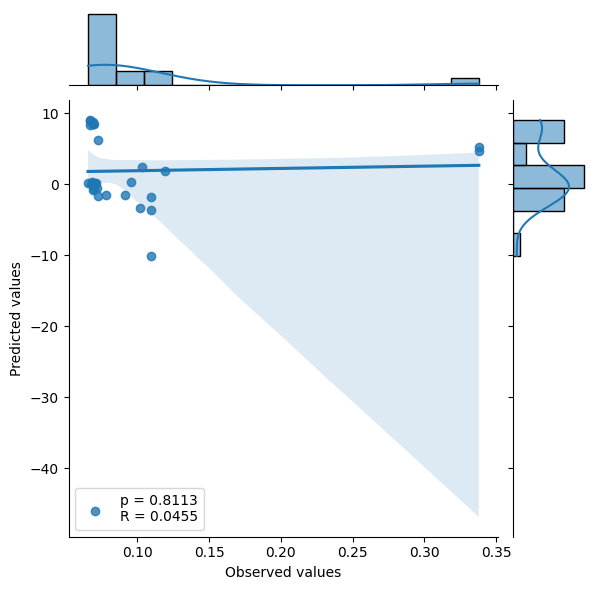

In [15]:
plt.figure(figsize=(15,15))
sns.jointplot(
    x=df_maior_erro.columns[col1_obt],
    y=df_maior_erro.columns[col2_prev],
    kind='reg',
    data=df_maior_erro#[df_maior_erro['Lista observado'] > 300]
)

if pear_pos_maior_erro[1] < 0.01:
  plt.legend(['p < ' + '0.01' + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e relse:
else:
  plt.legend(['p = ' + str(round(pear_pos_maior_erro[1],4)) + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e r

#Predição do modelo

In [16]:
predictions = modelo_maior_erro.predict(X_test_maior_erro)

1/1 [==============================] - 0s 427ms/step


In [17]:
# Compara as previsões com os valores reais
for i in range(len(predictions)):
    print(f"Valor real: {y_test_maior_erro[i]}, Valor predito: {predictions[i]}")

Valor real: 0.068888, Valor predito: [8.764543]
Valor real: 0.0689, Valor predito: [8.56191]
Valor real: 0.068904, Valor predito: [8.56191]
Valor real: 0.338015, Valor predito: [5.2117467]
Valor real: 0.070044, Valor predito: [8.554846]
Valor real: 0.072419, Valor predito: [-1.6810576]
Valor real: 0.070659, Valor predito: [0.08295958]
Valor real: 0.109643, Valor predito: [-10.063766]
Valor real: 0.065635, Valor predito: [0.19067328]
Valor real: 0.069308, Valor predito: [-0.7366653]
Valor real: 0.109804, Valor predito: [-1.796518]
Valor real: 0.067253, Valor predito: [9.0515175]
Valor real: 0.067018, Valor predito: [8.341032]
Valor real: 0.072419, Valor predito: [6.3152585]
Valor real: 0.095412, Valor predito: [0.31593934]
Valor real: 0.091715, Valor predito: [-1.5027176]
Valor real: 0.067253, Valor predito: [8.972588]
Valor real: 0.070178, Valor predito: [1.899572e-05]
Valor real: 0.069308, Valor predito: [0.1929373]
Valor real: 0.070864, Valor predito: [0.11581223]
Valor real: 0.10308

#Predição de Frequência Absoluta

In [18]:
df_maior_erro[:2]

,Observed values,Predicted values,Lista preditos
0,0.068888,8.76,8.764543
1,0.068900,8.56,8.561910


In [19]:
df_maior_erro['Diferença'] = df_maior_erro['Observed values'] - df_maior_erro['Predicted values']

In [20]:
df_maior_erro[:3]

,Observed values,Predicted values,Lista preditos,Diferença
0,0.068888,8.76,8.764543,-8.691112
1,0.068900,8.56,8.561910,-8.491100
2,0.068904,8.56,8.561910,-8.491096


In [21]:
import matplotlib.pyplot as plt

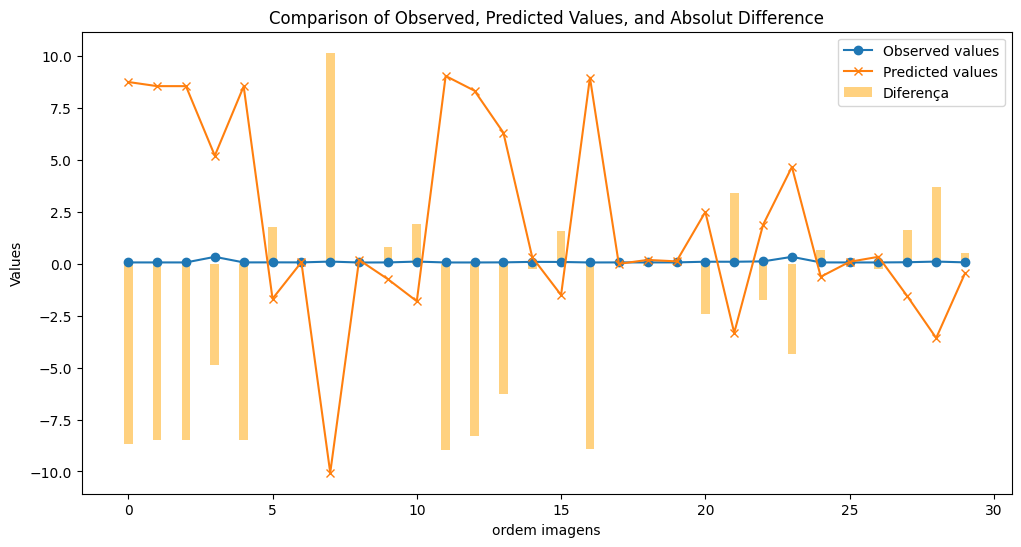

In [22]:
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença
plt.bar(df_maior_erro.index, df_maior_erro['Diferença'], width=0.3, alpha=0.5, label='Diferença', color='orange')

# Adiciona rótulos e título
plt.xlabel('ordem imagens')
plt.ylabel('Values')
plt.title('Comparison of Observed, Predicted Values, and Absolut Difference')
plt.legend()

# Mostra o gráfico
plt.show()

#Previsão Frequência Relativa (%)

In [23]:
df_maior_erro['Relative Difference (%)'] = ((df_maior_erro['Predicted values']*100) / df_maior_erro['Observed values'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos,Diferença,Relative Difference (%)
0,0.068888,8.76,8.764543,-8.691112,12716.293113
1,0.068900,8.56,8.561910,-8.491100,12423.802612
2,0.068904,8.56,8.561910,-8.491096,12423.081389
3,0.338015,5.21,5.211747,-4.871985,1541.351715
4,0.070044,8.55,8.554846,-8.479956,12206.612986


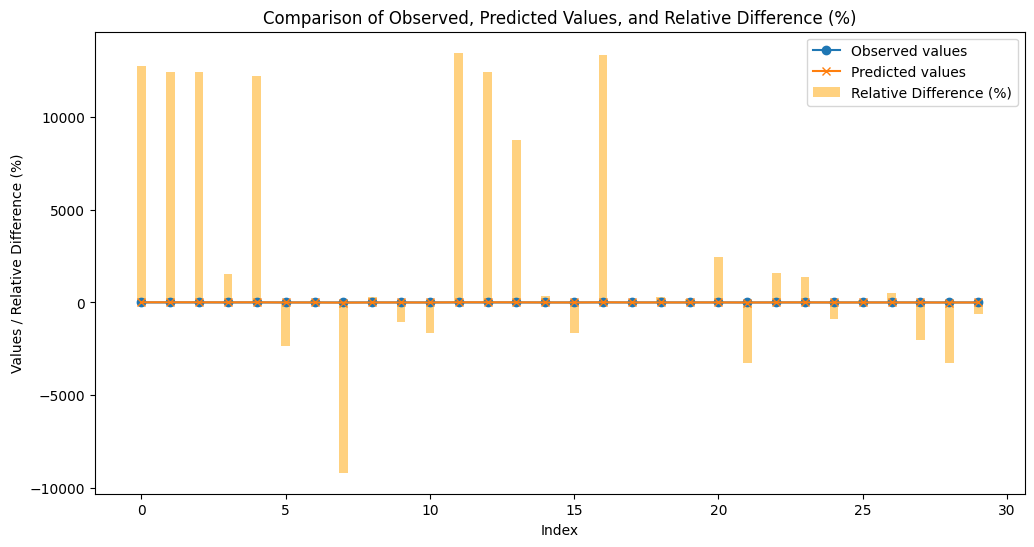

In [24]:
# Cria o gráfico comparando os valores
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença relativa
plt.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=0.3, alpha=0.5, label='Relative Difference (%)', color='orange')

# Adiciona rótulos e título
plt.xlabel('Index')
plt.ylabel('Values / Relative Difference (%)')
plt.title('Comparison of Observed, Predicted Values, and Relative Difference (%)')
plt.legend()

# Mostra o gráfico
plt.show()

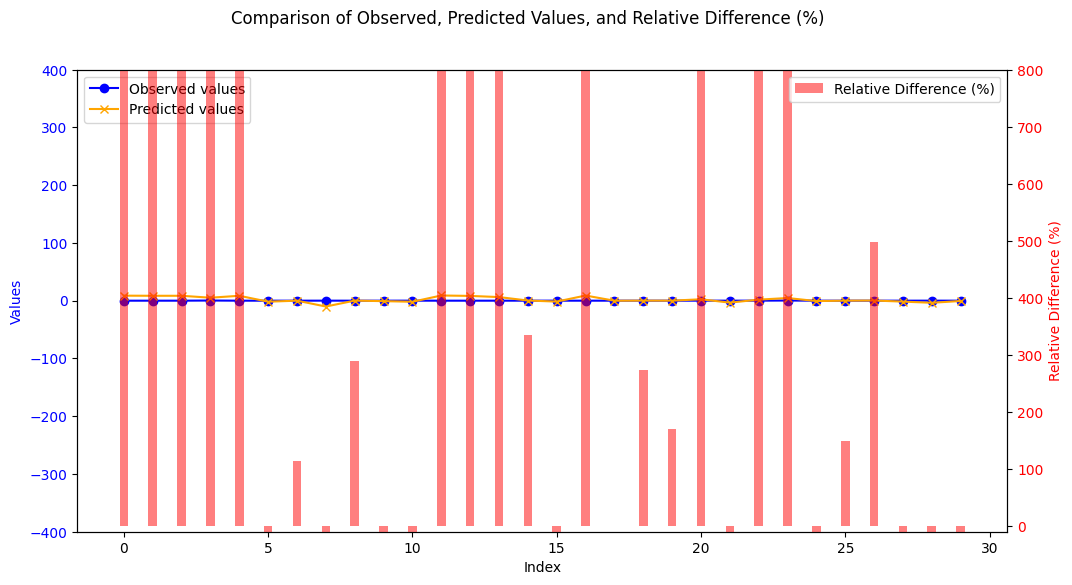

In [25]:
# Cria o gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Mantém a escala normal do eixo Y da esquerda
# ax1.set_ylim(df_maior_erro[['Observed values', 'Predicted values']].min().min(),
#              df_maior_erro[['Observed values', 'Predicted values']].max().max())
ax1.set_ylim(-400, 400)

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')


# Ajusta a largura das barras
bar_width = 0.3
ax2.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Corrige a amplitude do eixo Y da direita para -15 a 300
ax2.set_ylim(-10, 800)

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()